In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from cellpose import models, io

# -----------------------------
# PATHS
# -----------------------------
DATA_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei")
GT_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90")
CSV_PATH = Path("masks_to_correct_90.csv")

# -----------------------------
# LOAD SELECTION TABLE
# -----------------------------
subset_90 = pd.read_csv(CSV_PATH)

# -----------------------------
# HELPERS
# -----------------------------
def recursive_find(root: Path, filename: str):
    matches = list(root.rglob(filename))
    return matches[0] if matches else None

def find_original(base_name: str):
    exact = recursive_find(DATA_DIR, f"{base_name}.png")
    if exact is not None:
        return exact

    alt1 = recursive_find(DATA_DIR, f"{base_name.replace('_Positive_', '_control_')}.png")
    if alt1 is not None:
        return alt1

    alt2 = recursive_find(DATA_DIR, f"{base_name.replace('_control_', '_Positive_')}.png")
    if alt2 is not None:
        return alt2

    return None

def find_gt(base_name: str):
    return recursive_find(GT_DIR, f"{base_name}__gt.png")

# -----------------------------
# CELLPPOSE MODEL
# -----------------------------
model = models.CellposeModel(gpu=False, model_type='nuclei')

# -----------------------------
# STORE OUTPUTS
# -----------------------------
all_outputs = []

# -----------------------------
# LOOP THROUGH ALL 90 IMAGES
# -----------------------------
for _, row in subset_90.iterrows():
    base = row["image"]
    group = row["group"]

    img_path = find_original(base)
    gt_path = find_gt(base)

    if img_path is None:
        print(f"Skipping {base}: original image not found")
        continue
    if gt_path is None:
        print(f"Skipping {base}: GT mask not found")
        continue

    # 1. Load the image and Ground Truth mask
    img = io.imread(str(img_path))
    gt_mask_raw = io.imread(str(gt_path))

    if gt_mask_raw is None:
        print(f"Skipping {base}: GT could not be read")
        continue
    else:
        gt_mask = gt_mask_raw > 0

    # 2. Extract nuclei channel & Run Cellpose
    if img.ndim == 3:
        input_img = img[:, :, 0]   # ch0_nuclei
    else:
        input_img = img

    masks, flows, styles = model.eval(input_img, diameter=20, channels=[0, 0])

    # 3. Prepare Binary Masks for Dice Calculation
    pred_binary = masks > 0

    # Save outputs for Part 2
    all_outputs.append({
        "group": group,
        "image": base,
        "img": img,
        "gt_mask": gt_mask,
        "masks": masks,
        "pred_binary": pred_binary
    })

print("Part 1 finished.")
print("Images successfully processed:", len(all_outputs))

model_type argument is not used in v4.0.1+. Ignoring this argument...
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
channels deprecated in v4.0.1+. If data contain more than 

Part 1 finished.
Images successfully processed: 90


In [10]:
# Pick one example per group from all_outputs
examples_by_group = {}

for item in all_outputs:
    group = item["group"]
    if group not in examples_by_group:
        examples_by_group[group] = item

print("Groups found:")
for group in examples_by_group:
    print(group, "->", examples_by_group[group]["image"])

Groups found:
HCF_ECM -> HCF_ECM_A3_Image3.1__ch0_nuclei__y0800_x1200
HCF_Negative -> HCF_Negative_D3_Image1Merge__ch0_nuclei__y2000_x1200
HCF_Positive -> HCF_Positive_C4_Image2.2__ch0_nuclei__y0400_x0800
HDF_ECM -> HDF_ECM_B5_Image4Merge__ch0_nuclei__y2400_x0800
HDF_Negative -> HDF_Negative_D5_Image1.2__ch0_nuclei__y0400_x0000
HDF_Positive -> HDF_Positive_C6_Image1Merge__ch0_nuclei__y2400_x4000
HFOB_ECM -> HFOB_ECM_C1_Image1Merge__ch0_nuclei__y1600_x0000
HFOB_Negative -> HFOB_Negative_D1_Image1Merge__ch0_nuclei__y0000_x1600
HFOB_Positive -> HFOB_Positive_A2_Image2.5__ch0_nuclei__y0000_x1200


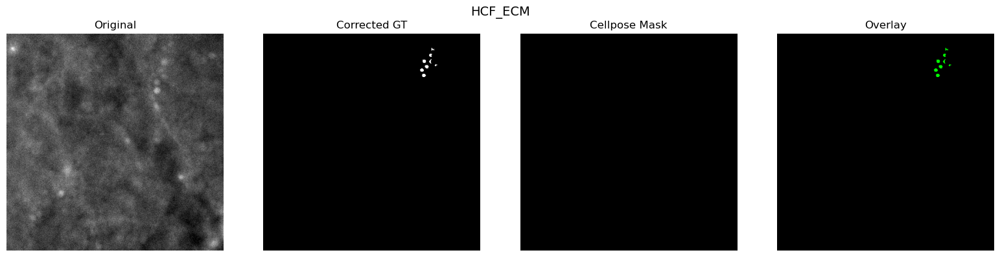

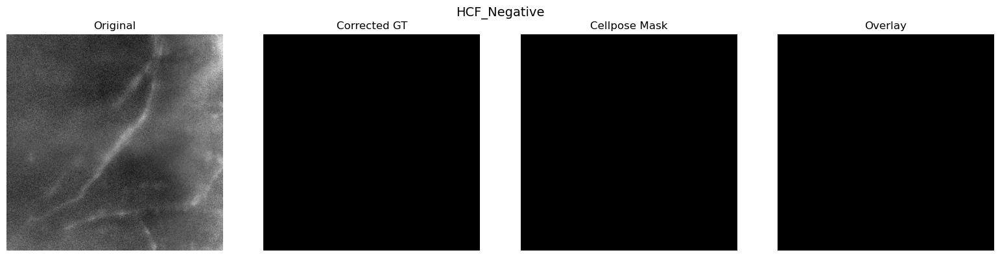

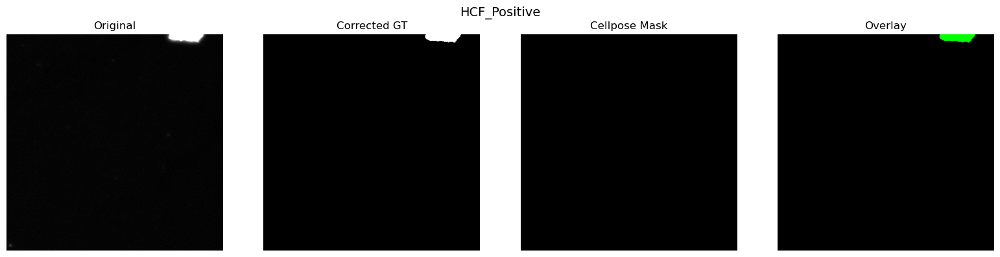

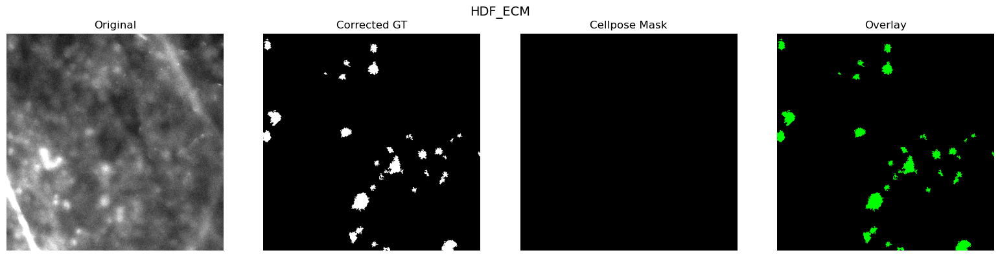

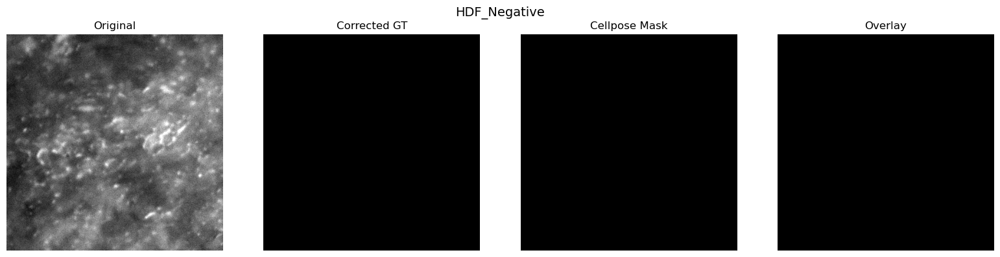

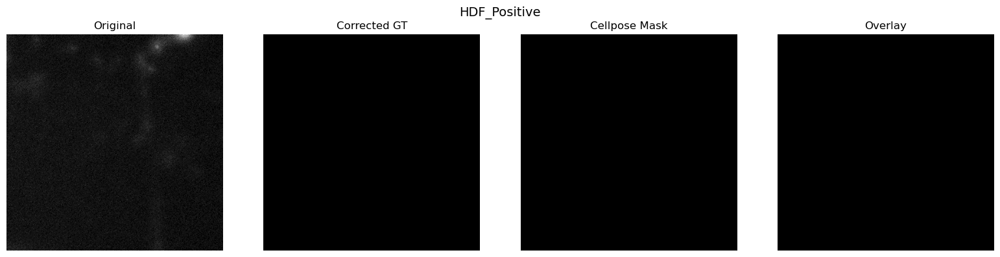

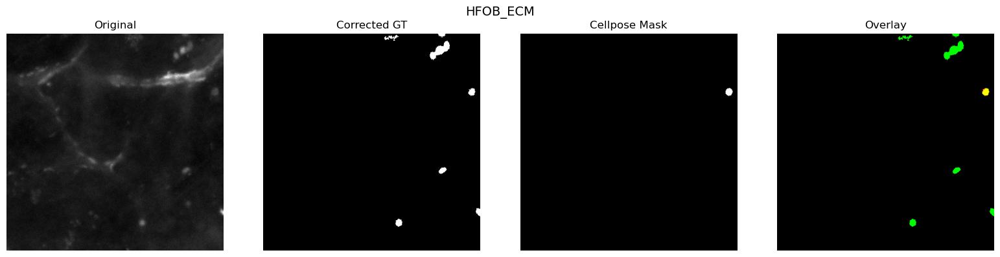

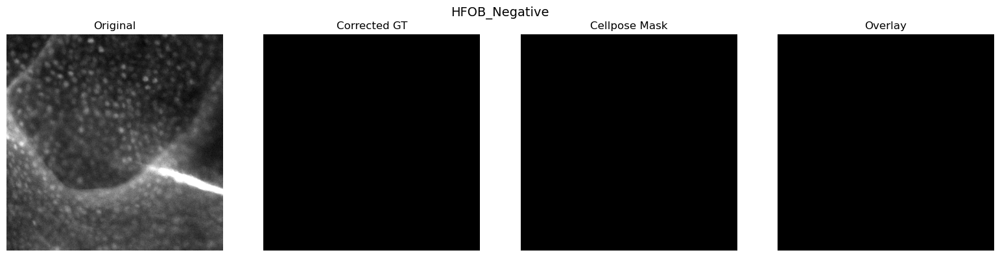

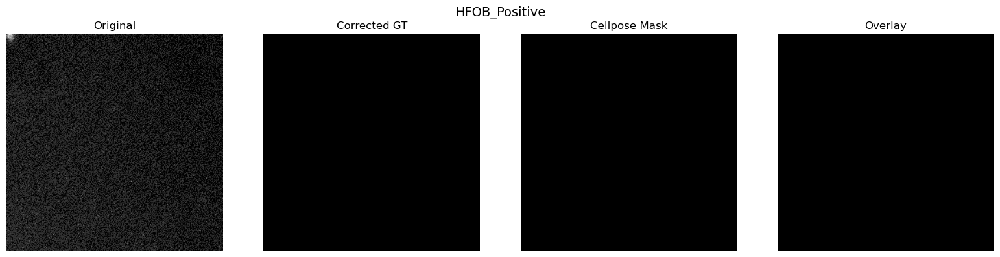

Saved figures to: /Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/THESIS_FIGURES_SEGMENTATION


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/THESIS_FIGURES_SEGMENTATION")
FIG_DIR.mkdir(parents=True, exist_ok=True)

for group, example in examples_by_group.items():
    img = example["img"]
    gt = example["gt_mask"]
    pred = example["pred_binary"]

    # make overlay: red = prediction, green = GT
    overlay = np.zeros((*gt.shape, 3), dtype=np.uint8)
    overlay[..., 0] = pred.astype(np.uint8) * 255
    overlay[..., 1] = gt.astype(np.uint8) * 255

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    ax[0].imshow(img, cmap="gray")
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(gt, cmap="gray")
    ax[1].set_title("Corrected GT")
    ax[1].axis("off")

    ax[2].imshow(pred, cmap="gray")
    ax[2].set_title("Cellpose Mask")
    ax[2].axis("off")

    ax[3].imshow(overlay)
    ax[3].set_title("Overlay")
    ax[3].axis("off")

    plt.suptitle(group, fontsize=14)
    plt.tight_layout()

    out_path = FIG_DIR / f"{group}_segmentation_example.png"
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Saved figures to:", FIG_DIR)

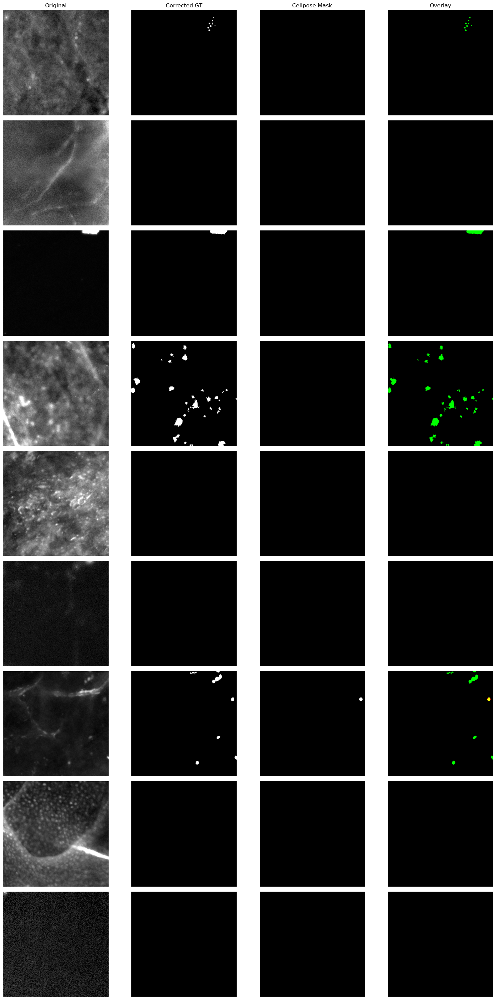

Saved combined figure to: /Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/THESIS_FIGURES_SEGMENTATION/all_groups_segmentation_examples.png


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

group_order = [
    "HCF_ECM", "HCF_Negative", "HCF_Positive",
    "HDF_ECM", "HDF_Negative", "HDF_Positive",
    "HFOB_ECM", "HFOB_Negative", "HFOB_Positive"
]

fig, axes = plt.subplots(9, 4, figsize=(16, 30))

for r, group in enumerate(group_order):
    example = examples_by_group[group]
    img = example["img"]
    gt = example["gt_mask"]
    pred = example["pred_binary"]

    overlay = np.zeros((*gt.shape, 3), dtype=np.uint8)
    overlay[..., 0] = pred.astype(np.uint8) * 255
    overlay[..., 1] = gt.astype(np.uint8) * 255

    panels = [img, gt, pred, overlay]
    titles = ["Original", "Corrected GT", "Cellpose Mask", "Overlay"]

    for c in range(4):
        ax = axes[r, c]
        if c == 3:
            ax.imshow(panels[c])
        else:
            ax.imshow(panels[c], cmap="gray")
        ax.axis("off")
        if r == 0:
            ax.set_title(titles[c], fontsize=12)
        if c == 0:
            ax.set_ylabel(group, rotation=90, fontsize=12, labelpad=15)

plt.tight_layout()
combined_path = FIG_DIR / "all_groups_segmentation_examples.png"
plt.savefig(combined_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved combined figure to:", combined_path)

Part 2 finished.
Rows scored: 90

Overall summary:
            dice        iou  boot_mean   boot_std
count  90.000000  90.000000  90.000000  90.000000
mean    0.386543   0.345640   0.386520   0.002197
std     0.431958   0.402955   0.431910   0.003162
min     0.000000   0.000000   0.000000   0.000000
25%     0.000000   0.000000   0.000000   0.000000
50%     0.000000   0.000000   0.000000   0.000000
75%     0.904100   0.824985   0.903794   0.003183
max     0.978288   0.957498   0.978312   0.014212

Group means:
                   dice       iou  boot_mean  boot_std
group                                                 
HCF_ECM        0.485600  0.398794   0.485634  0.003654
HCF_Negative   0.073687  0.058337   0.073722  0.000750
HCF_Positive   0.636014  0.584083   0.635925  0.002114
HDF_ECM        0.416250  0.330004   0.416383  0.006248
HDF_Negative   0.000000  0.000000   0.000000  0.000000
HDF_Positive   0.654131  0.614970   0.654005  0.002143
HFOB_ECM       0.380044  0.342050   0.379985 

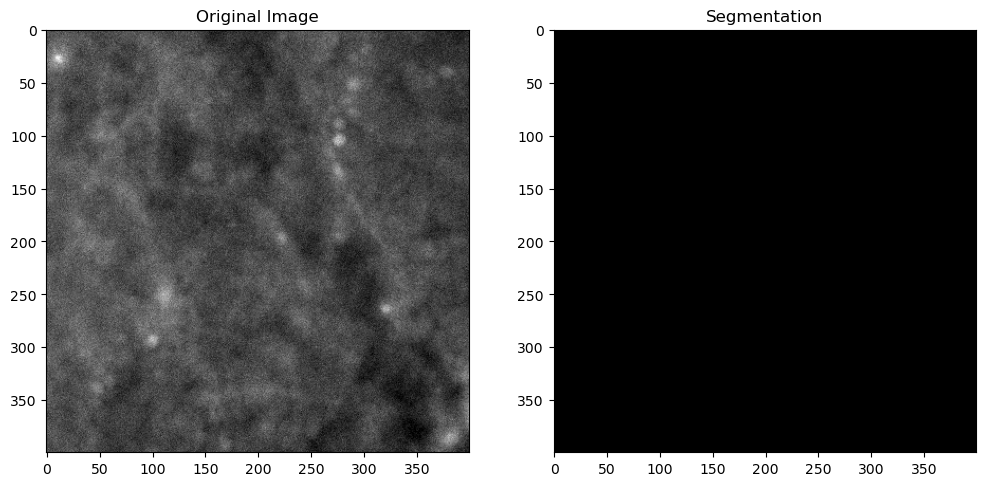

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 4. Calculate Dice Score
def calculate_dice(pred, gt):
    intersection = np.logical_and(pred, gt).sum()
    denominator = pred.sum() + gt.sum()
    if denominator == 0:
        return 0.0
    return (2.0 * intersection) / denominator

# IoU
def calculate_iou(pred, gt):
    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    if union == 0:
        return 0.0
    return intersection / union

# Bootstrap Dice
def bootstrap_dice(y_true, y_pred, n=300):
    flat_true = y_true.flatten().astype(np.uint8)
    flat_pred = y_pred.flatten().astype(np.uint8)
    scores = []
    N = len(flat_true)

    for _ in range(n):
        idx = np.random.choice(N, N, replace=True)
        inter = np.sum(flat_true[idx] * flat_pred[idx])
        denom = np.sum(flat_true[idx]) + np.sum(flat_pred[idx])
        if denom == 0:
            scores.append(0.0)
        else:
            scores.append(2.0 * inter / denom)

    return np.array(scores)

# Store final results
results = []

for item in all_outputs:
    base = item["image"]
    group = item["group"]
    img = item["img"]
    gt_mask = item["gt_mask"]
    masks = item["masks"]
    pred_binary = item["pred_binary"]

    # Shape check
    if pred_binary.shape != gt_mask.shape:
        print(f"Skipping {base}: shape mismatch {pred_binary.shape} vs {gt_mask.shape}")
        continue

    dice = calculate_dice(pred_binary, gt_mask)
    iou = calculate_iou(pred_binary, gt_mask)
    boot = bootstrap_dice(gt_mask, pred_binary, n=300)

    results.append({
        "group": group,
        "image": base,
        "dice": dice,
        "iou": iou,
        "boot_mean": boot.mean(),
        "boot_std": boot.std()
    })

results_df = pd.DataFrame(results)

print("Part 2 finished.")
print("Rows scored:", len(results_df))

print("\nOverall summary:")
print(results_df[["dice", "iou", "boot_mean", "boot_std"]].describe())

print("\nGroup means:")
print(results_df.groupby("group")[["dice", "iou", "boot_mean", "boot_std"]].mean())

# Optional visualization
example_idx = 0

if len(all_outputs) > 0:
    ex = all_outputs[example_idx]

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(ex["img"], cmap="gray")
    ax[0].set_title("Original Image")
    ax[1].imshow(ex["masks"], cmap='nipy_spectral')
    ax[1].set_title("Segmentation")
    plt.show()

In [11]:
#Morphometric analysis
#Imports

import os
import re
import numpy as np
import pandas as pd
import imageio.v3 as iio
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import mannwhitneyu
from skimage.measure import label, regionprops_table
from cellpose import models

In [12]:
#Folders

BASE_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei")

INPUT_FOLDERS = [
    BASE_DIR / "HCF_control_nuclei",
    BASE_DIR / "HCF_ECM_nuclei",
    BASE_DIR / "HDF_control_nuclei",
    BASE_DIR / "HDF_ECM_nuclei",
    BASE_DIR / "HFOB_control_nuclei",
    BASE_DIR / "HFOB_ECM_nuclei",
]

OUT_DIR = BASE_DIR / "ALL_CELLPOSE_ECM_POS"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUT_DIR)
for folder in INPUT_FOLDERS:
    print(folder, "exists:", folder.exists())

Output folder: /Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/ALL_CELLPOSE_ECM_POS
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HCF_control_nuclei exists: True
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HCF_ECM_nuclei exists: True
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HDF_control_nuclei exists: True
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HDF_ECM_nuclei exists: True
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HFOB_control_nuclei exists: True
/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HFOB_ECM_nuclei exists: True


In [19]:
#Tiles

image_files = []

for folder in INPUT_FOLDERS:
    image_files.extend(sorted(folder.glob("*.png")))

print("Total image tiles found:", len(image_files))
for f in image_files[:10]:
    print(f.name)

Total image tiles found: 7977
HCF_Positive_A4_Image1.1__ch0_nuclei__y0000_x0000.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0000_x0400.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0000_x0800.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0000_x1200.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0400_x0000.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0400_x0400.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0400_x0800.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0400_x1200.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0800_x0000.png
HCF_Positive_A4_Image1.1__ch0_nuclei__y0800_x0400.png


In [20]:
## import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import imageio.v3 as iio
from cellpose import models

# =========================
# SETTINGS
# =========================
DATA_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei")
OUT_DIR = DATA_DIR / "CELLPPOSE_PRED_100_CONTROL_ECM"
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_PER_FOLDER = 100
RANDOM_SEED = 42
NUC_DIAMETER = 25

# =========================
# FIND ONLY CONTROL + ECM FOLDERS
# =========================
random.seed(RANDOM_SEED)

target_folders = sorted([
    f for f in DATA_DIR.iterdir()
    if f.is_dir()
    and f.name.endswith("_nuclei")
    and ("control" in f.name.lower() or "ecm" in f.name.lower())
])

print("Condition folders being used:")
for f in target_folders:
    print("-", f.name)

# =========================
# SAMPLE 100 IMAGES PER FOLDER
# =========================
image_files = []

for folder in target_folders:
    folder_imgs = sorted(folder.glob("*.png"))

    if len(folder_imgs) == 0:
        print(f"Skipping {folder.name}: no PNG files found")
        continue

    n_take = min(N_PER_FOLDER, len(folder_imgs))
    sampled = random.sample(folder_imgs, n_take)
    image_files.extend(sampled)

    print(f"{folder.name}: sampled {n_take} images")

print(f"\nTotal sampled images: {len(image_files)}")

# Save sampling record
sample_df = pd.DataFrame({
    "image_path": [str(p) for p in image_files],
    "folder": [p.parent.name for p in image_files],
    "file_name": [p.name for p in image_files]
})
sample_csv = OUT_DIR / "sampled_control_ecm_images.csv"
sample_df.to_csv(sample_csv, index=False)
print(f"Sampling record saved: {sample_csv.name}")

# =========================
# RUN CELLPOSE SEGMENTATION
# =========================
print("\nLoading Cellpose model...")
model = models.CellposeModel(gpu=False)

saved_masks = []
start_time = time.time()

for i, img_path in enumerate(image_files, start=1):
    img = iio.imread(img_path)

    # If RGB, use blue channel for nuclei
    if img.ndim == 3:
        nuc_img = img[:, :, 2]
    else:
        nuc_img = img

    masks, flows, styles = model.eval(
        nuc_img,
        diameter=NUC_DIAMETER,
        channels=[0, 0]
    )

    pred_mask = (masks > 0).astype(np.uint8) * 255
    out_name = img_path.stem + "_pred.png"
    out_path = OUT_DIR / out_name
    iio.imwrite(out_path, pred_mask)
    saved_masks.append(out_path)

    # progress update every 10 images
    if i % 10 == 0 or i == len(image_files):
        elapsed = time.time() - start_time
        avg_sec = elapsed / i
        remaining_min = ((len(image_files) - i) * avg_sec) / 60
        print(f"Processed {i}/{len(image_files)} | avg {avg_sec:.2f} sec/img | est remaining {remaining_min:.1f} min")

# =========================
# FINAL SUMMARY
# =========================
total_time = time.time() - start_time

print("\nSegmentation complete.")
print("Saved masks:", len(saved_masks))
print(f"Output folder: {OUT_DIR}")
print(f"Total time: {total_time/60:.2f} minutes")
print(f"Average time per image: {total_time/len(image_files):.2f} seconds")

NameError: name 'random' is not defined

In [13]:
#Base folder

BASE_DIR = Path("/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_100_CONTROL_ECM")
print("Base folder exists:", BASE_DIR.exists())
print("Folders found:")
for f in sorted(BASE_DIR.iterdir()):
    if f.is_dir():
        print("-", f.name)

Base folder exists: True
Folders found:
- HCF_ECM
- HCF_Positive
- HDF_ECM
- HDF_Positive
- HFOB_ECM
- HFOB_Positive


In [14]:
#Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import imageio.v3 as iio

from scipy.stats import mannwhitneyu
from skimage.measure import regionprops, label

In [15]:
#Helper functions

def normalize_cell_type(name):
    name = name.strip().upper()
    if name == "HCF":
        return "HCF"
    elif name == "HDF":
        return "HDF"
    elif name == "HFOB":
        return "hFOB"
    else:
        return name

def normalize_condition(name):
    name = name.strip().lower()
    if "ecm" in name:
        return "ECM"
    elif "positive" in name:
        return "Positive"
    else:
        return name

def parse_folder_name(folder_name):
    parts = folder_name.split("_")
    if len(parts) < 2:
        return None, None
    
    raw_cell = parts[0]
    raw_condition = "_".join(parts[1:])
    
    cell_type = normalize_cell_type(raw_cell)
    condition = normalize_condition(raw_condition)
    return cell_type, condition

def get_mask_files(folder):
    files = []
    for ext in ["*.png", "*.tif", "*.tiff", "*.jpg", "*.jpeg"]:
        files.extend(folder.glob(ext))
    return sorted(files)

def load_mask(mask_path):
    mask = iio.imread(mask_path)
    mask = np.squeeze(mask)
    return mask

def compute_nuclear_features(mask):
    """
    Computes area, circularity, eccentricity for each labeled nucleus.
    Assumes mask is a labeled segmentation mask:
    background = 0, nuclei = 1,2,3,...
    """
    if mask.ndim != 2:
        return []
    
    # If mask is binary, relabel it
    unique_vals = np.unique(mask)
    if set(unique_vals).issubset({0, 1}):
        labeled_mask = label(mask > 0)
    else:
        labeled_mask = mask.astype(int)

    props = regionprops(labeled_mask)
    results = []

    for prop in props:
        area = prop.area
        perimeter = prop.perimeter
        
        if perimeter == 0:
            circularity = np.nan
        else:
            circularity = (4 * np.pi * area) / (perimeter ** 2)
        
        eccentricity = prop.eccentricity
        
        results.append({
            "area": float(area),
            "circularity": float(circularity) if not np.isnan(circularity) else np.nan,
            "eccentricity": float(eccentricity)
        })
    
    return results

In [16]:
#Morphometric measurements

all_measurements = []

for folder in sorted(BASE_DIR.iterdir()):
    if not folder.is_dir():
        continue
    
    cell_type, condition = parse_folder_name(folder.name)
    
    print(f"\nProcessing: {folder.name}")
    print("  Parsed cell type:", cell_type)
    print("  Parsed condition:", condition)
    
    if cell_type is None or condition not in ["ECM", "Positive"]:
        print("  Skipped: folder name not recognized")
        continue
    
    mask_files = get_mask_files(folder)
    print("  Mask files found:", len(mask_files))
    
    for file in mask_files:
        try:
            mask = load_mask(file)
            feature_list = compute_nuclear_features(mask)
            
            for i, feat in enumerate(feature_list):
                all_measurements.append({
                    "cell_type": cell_type,
                    "condition": condition,
                    "image_name": file.name,
                    "nucleus_id": i + 1,
                    "area": feat["area"],
                    "circularity": feat["circularity"],
                    "eccentricity": feat["eccentricity"]
                })
        except Exception as e:
            print(f"  Error reading {file.name}: {e}")

morph_df = pd.DataFrame(all_measurements)

print("\nFinished.")
print("Total nuclei measured:", len(morph_df))
print(morph_df.head())


Processing: HCF_ECM
  Parsed cell type: HCF
  Parsed condition: ECM
  Mask files found: 100

Processing: HCF_Positive
  Parsed cell type: HCF
  Parsed condition: Positive
  Mask files found: 100

Processing: HDF_ECM
  Parsed cell type: HDF
  Parsed condition: ECM
  Mask files found: 100

Processing: HDF_Positive
  Parsed cell type: HDF
  Parsed condition: Positive
  Mask files found: 100

Processing: HFOB_ECM
  Parsed cell type: hFOB
  Parsed condition: ECM
  Mask files found: 100

Processing: HFOB_Positive
  Parsed cell type: hFOB
  Parsed condition: Positive
  Mask files found: 100

Finished.
Total nuclei measured: 509
  cell_type condition                                         image_name  \
0       HCF       ECM  HCF_ECM_A3_Image1Merge__ch0_nuclei__y0800_x280...   
1       HCF       ECM  HCF_ECM_A3_Image1Merge__ch0_nuclei__y1600_x320...   
2       HCF       ECM  HCF_ECM_A3_Image1Merge__ch0_nuclei__y2000_x080...   
3       HCF       ECM  HCF_ECM_A3_Image2.1__ch0_nuclei__y0800_x120

In [17]:
#Count

group_counts = morph_df.groupby(["cell_type", "condition"]).size().reset_index(name="n_nuclei")
print(group_counts)

  cell_type condition  n_nuclei
0       HCF       ECM        76
1       HCF  Positive        95
2       HDF       ECM        66
3       HDF  Positive        97
4      hFOB       ECM        80
5      hFOB  Positive        95


In [18]:
#Statistics

summary_stats = (
    morph_df.groupby(["cell_type", "condition"])
    .agg(
        n_nuclei=("area", "count"),
        area_mean=("area", "mean"),
        area_median=("area", "median"),
        area_sd=("area", "std"),
        circularity_mean=("circularity", "mean"),
        circularity_median=("circularity", "median"),
        circularity_sd=("circularity", "std"),
        eccentricity_mean=("eccentricity", "mean"),
        eccentricity_median=("eccentricity", "median"),
        eccentricity_sd=("eccentricity", "std")
    )
    .reset_index()
)

print(summary_stats)

  cell_type condition  n_nuclei     area_mean  area_median      area_sd  \
0       HCF       ECM        76   5089.644737       5047.0  3773.433449   
1       HCF  Positive        95  10891.105263       9130.0  7548.882329   
2       HDF       ECM        66   4036.621212       1798.5  5355.331706   
3       HDF  Positive        97   5011.505155       3512.0  4767.540133   
4      hFOB       ECM        80   4910.412500       2715.5  5082.335097   
5      hFOB  Positive        95   7828.673684       5171.0  8107.672550   

   circularity_mean  circularity_median  circularity_sd  eccentricity_mean  \
0          0.196400            0.079124        0.226892           0.750453   
1          0.098394            0.045254        0.132706           0.656220   
2          0.235407            0.162314        0.226502           0.850779   
3          0.193477            0.135563        0.173658           0.756049   
4          0.219273            0.102850        0.280013           0.741723   
5     

In [19]:
#Mann-Whitney test

stats_results = []

for cell in sorted(morph_df["cell_type"].unique()):
    for feature in ["area", "circularity", "eccentricity"]:
        ecm = morph_df[
            (morph_df["cell_type"] == cell) &
            (morph_df["condition"] == "ECM")
        ][feature].dropna()

        pos = morph_df[
            (morph_df["cell_type"] == cell) &
            (morph_df["condition"] == "Positive")
        ][feature].dropna()

        if len(ecm) > 0 and len(pos) > 0:
            u_stat, p_val = mannwhitneyu(ecm, pos, alternative="two-sided")
        else:
            u_stat, p_val = np.nan, np.nan

        stats_results.append({
            "cell_type": cell,
            "feature": feature,
            "ECM_n": len(ecm),
            "Positive_n": len(pos),
            "ECM_median": ecm.median() if len(ecm) > 0 else np.nan,
            "Positive_median": pos.median() if len(pos) > 0 else np.nan,
            "U_statistic": u_stat,
            "p_value": p_val
        })

stats_df = pd.DataFrame(stats_results)
print(stats_df)

  cell_type       feature  ECM_n  Positive_n   ECM_median  Positive_median  \
0       HCF          area     76          95  5047.000000      9130.000000   
1       HCF   circularity     76          95     0.079124         0.045254   
2       HCF  eccentricity     76          95     0.784922         0.652011   
3       HDF          area     66          97  1798.500000      3512.000000   
4       HDF   circularity     66          97     0.162314         0.135563   
5       HDF  eccentricity     66          97     0.898020         0.765669   
6      hFOB          area     80          95  2715.500000      5171.000000   
7      hFOB   circularity     80          95     0.102850         0.062285   
8      hFOB  eccentricity     80          95     0.772743         0.692271   

   U_statistic       p_value  
0       1928.0  1.722581e-07  
1       4806.0  2.021847e-04  
2       4517.0  4.833883e-03  
3       2151.0  3.880515e-04  
4       3464.0  3.748408e-01  
5       4125.0  1.795617e-03  
6 

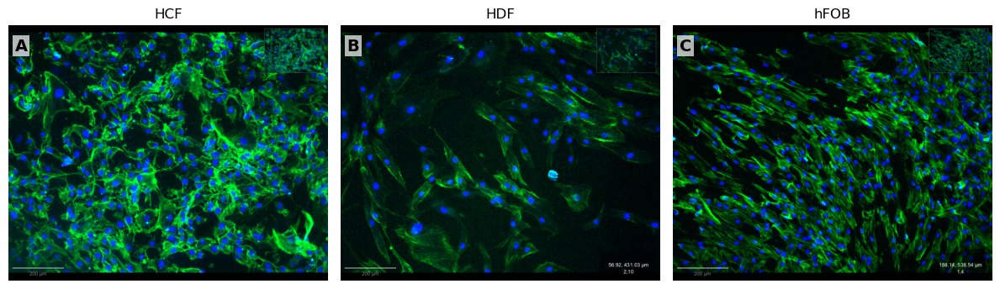

Saved panel to: /Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS/positive_controls_panel_labeled.png


In [5]:
# ==========================================
# POSITIVE CONTROL PNGs -> 3-PANEL FIGURE
# WITH A, B, C LABELS
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import imageio.v3 as iio

# ------------------------------------------
# EDIT THESE PATHS
# ------------------------------------------
img1_path = "/Users/catalinaamurrio/Desktop/Thesis/HCF Positive.png"
img2_path = "/Users/catalinaamurrio/Desktop/Thesis/HDF Positive.png"
img3_path = "/Users/catalinaamurrio/Desktop/Thesis/HFOB Positive.png"

labels = ["HCF", "HDF", "hFOB"]
panel_letters = ["A", "B", "C"]

output_dir = Path("/Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "positive_controls_panel_labeled.png"

# ------------------------------------------
# LOAD
# ------------------------------------------
images = [
    iio.imread(img1_path),
    iio.imread(img2_path),
    iio.imread(img3_path)
]

# ------------------------------------------
# PLOT
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, label, letter in zip(axes, images, labels, panel_letters):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.axis("off")
    ax.set_title(label, fontsize=12)
    
    ax.text(
        0.02, 0.95, letter,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2)
    )

plt.tight_layout()
plt.savefig(output_file, dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

print(f"Saved panel to: {output_file}")

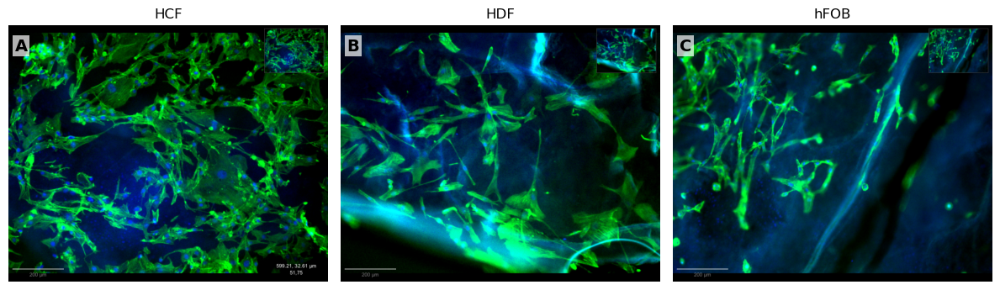

Saved panel to: /Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS/ECM_panel_labeled.png


In [6]:
# ==========================================
# POSITIVE CONTROL PNGs -> 3-PANEL FIGURE
# WITH A, B, C LABELS
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import imageio.v3 as iio

# ------------------------------------------
# EDIT THESE PATHS
# ------------------------------------------
img1_path = "/Users/catalinaamurrio/Desktop/Thesis/HCF ECM.png"
img2_path = "/Users/catalinaamurrio/Desktop/Thesis/HDF ECM.png"
img3_path = "/Users/catalinaamurrio/Desktop/Thesis/HFOB ECM.png"

labels = ["HCF", "HDF", "hFOB"]
panel_letters = ["A", "B", "C"]

output_dir = Path("/Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "ECM_panel_labeled.png"

# ------------------------------------------
# LOAD
# ------------------------------------------
images = [
    iio.imread(img1_path),
    iio.imread(img2_path),
    iio.imread(img3_path)
]

# ------------------------------------------
# PLOT
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, label, letter in zip(axes, images, labels, panel_letters):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.axis("off")
    ax.set_title(label, fontsize=12)
    
    ax.text(
        0.02, 0.95, letter,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2)
    )

plt.tight_layout()
plt.savefig(output_file, dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

print(f"Saved panel to: {output_file}")

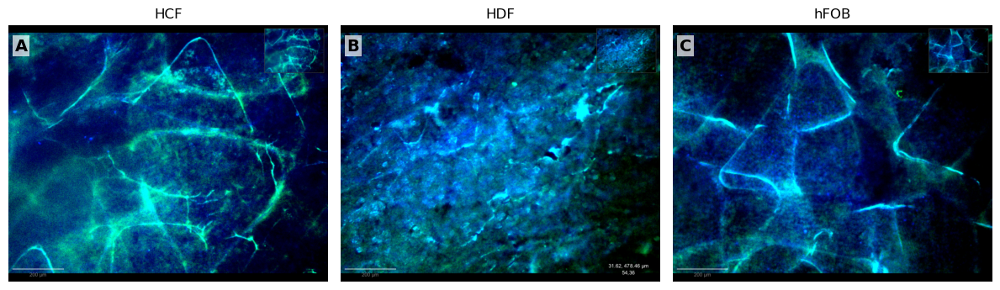

Saved panel to: /Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS/negative_control_panel_labeled.png


In [7]:
# ==========================================
# POSITIVE CONTROL PNGs -> 3-PANEL FIGURE
# WITH A, B, C LABELS
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import imageio.v3 as iio

# ------------------------------------------
# EDIT THESE PATHS
# ------------------------------------------
img1_path = "/Users/catalinaamurrio/Desktop/Thesis/HCF Negative.png"
img2_path = "/Users/catalinaamurrio/Desktop/Thesis/HDF Negative.png"
img3_path = "/Users/catalinaamurrio/Desktop/Thesis/HFOB Negative.png"

labels = ["HCF", "HDF", "hFOB"]
panel_letters = ["A", "B", "C"]

output_dir = Path("/Users/catalinaamurrio/Desktop/Thesis/PAPER_PANELS")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "negative_control_panel_labeled.png"

# ------------------------------------------
# LOAD
# ------------------------------------------
images = [
    iio.imread(img1_path),
    iio.imread(img2_path),
    iio.imread(img3_path)
]

# ------------------------------------------
# PLOT
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img, label, letter in zip(axes, images, labels, panel_letters):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.axis("off")
    ax.set_title(label, fontsize=12)
    
    ax.text(
        0.02, 0.95, letter,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2)
    )

plt.tight_layout()
plt.savefig(output_file, dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

print(f"Saved panel to: {output_file}")

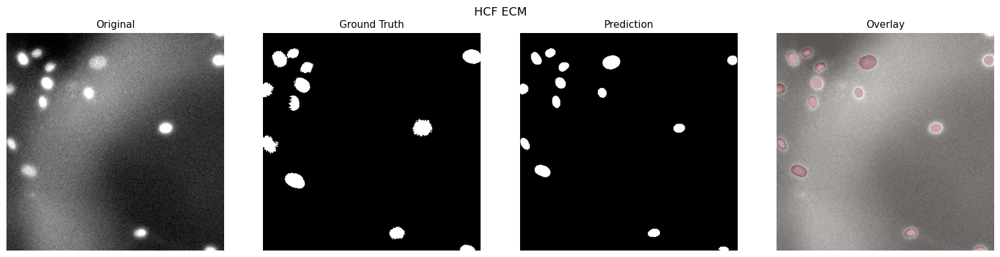

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_1_HCF_ECM.png


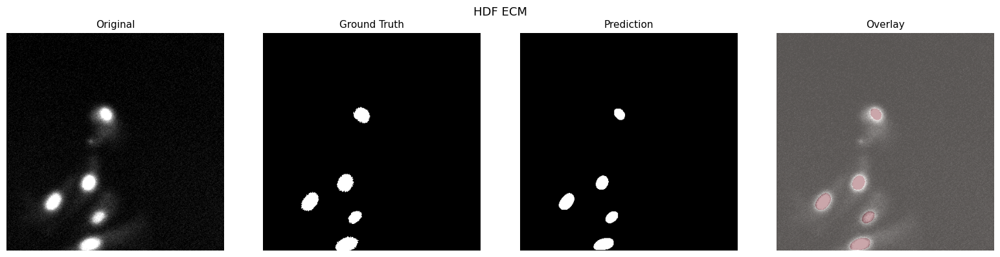

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_2_HDF_ECM.png


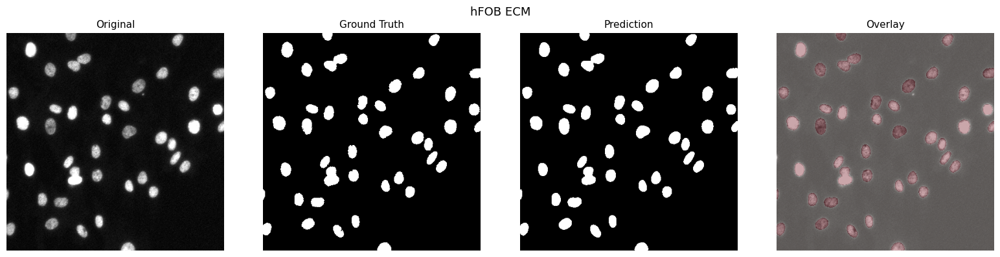

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_3_hFOB_ECM.png


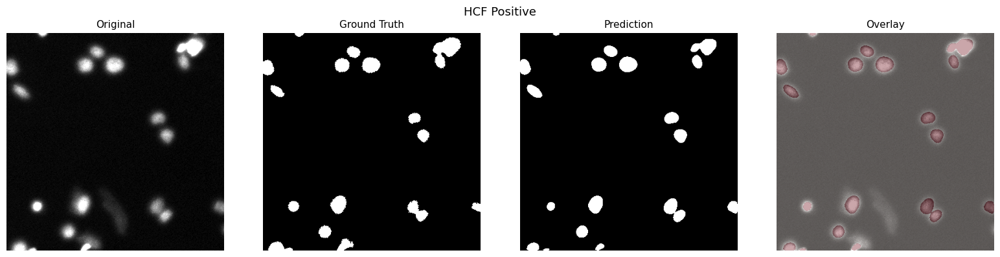

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_4_HCF_Positive.png


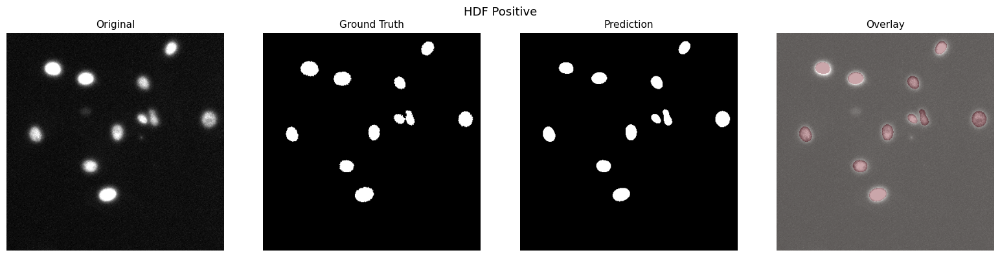

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_5_HDF_Positive.png


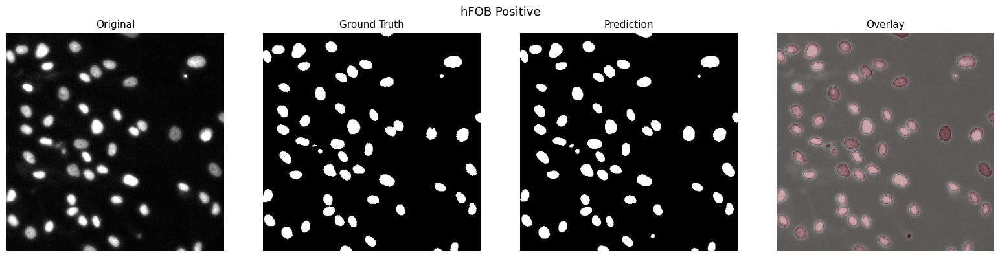

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_6_hFOB_Positive.png


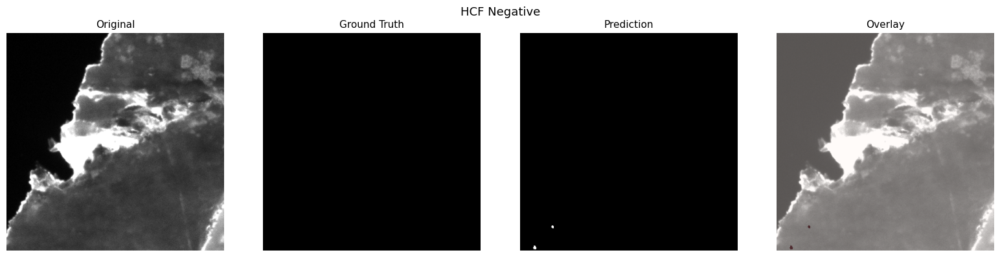

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_7_HCF_Negative.png


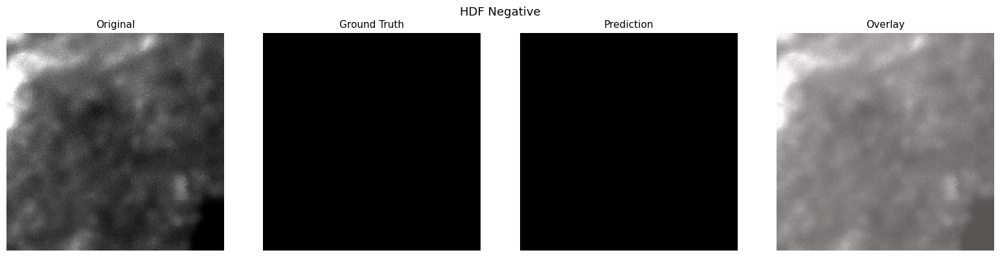

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_8_HDF_Negative.png


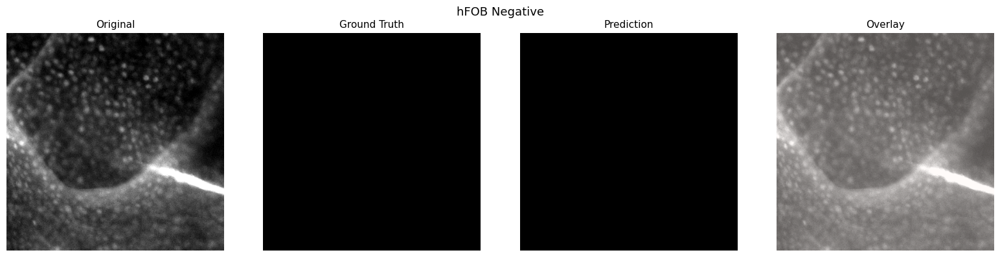

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS/segmentation_panel_9_hFOB_Negative.png


In [10]:
# =========================================================
# FIXED CODE: Representative segmentation panels
# =========================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile as tiff
import imageio.v3 as iio

# ---------------------------------------------------------
# Each item = (pred_mask_path, gt_mask_path, original_image_path)
# ---------------------------------------------------------
selected_samples = [
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HCF_ECM_A3_Image2.1__ch0_nuclei__y0400_x0000__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HCF_ECM_A3_Image2.1__ch0_nuclei__y0400_x0000__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HCF_ECM_nuclei/HCF_ECM_A3_Image2.1__ch0_nuclei__y0400_x0000.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HDF_ECM_A5_Image1Merge__ch0_nuclei__y1200_x0000__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HDF_ECM_A5_Image1Merge__ch0_nuclei__y1200_x0000__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HDF_ECM_nuclei/HDF_ECM_A5_Image1Merge__ch0_nuclei__y1200_x0000.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HFOB_ECM_B1_Image1.3__ch0_nuclei__y0800_x0000__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HFOB_ECM_B1_Image1.3__ch0_nuclei__y0800_x0000__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HFOB_ECM_nuclei/HFOB_ECM_B1_Image1.3__ch0_nuclei__y0800_x0000.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HCF_Positive_A4_Image1.5__ch0_nuclei__y0800_x1200__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HCF_Positive_A4_Image1.5__ch0_nuclei__y0800_x1200__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HCF_control_nuclei/HCF_Positive_A4_Image1.5__ch0_nuclei__y0800_x1200.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HDF_Positive_A6_Image2.2__ch0_nuclei__y0800_x0000__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HDF_Positive_A6_Image2.2__ch0_nuclei__y0800_x0000__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HDF_control_nuclei/HDF_Positive_A6_Image2.2__ch0_nuclei__y0800_x0000.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HFOB_Positive_A2_Image2Merge__ch0_nuclei__y0400_x2400__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HFOB_Positive_A2_Image2Merge__ch0_nuclei__y0400_x2400__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HFOB_control_nuclei/HFOB_Positive_A2_Image2Merge__ch0_nuclei__y0400_x2400.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HCF_Negative_D3_Image1Merge__ch0_nuclei__y0400_x4000__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HCF_Negative_D3_Image1Merge__ch0_nuclei__y0400_x4000__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HCF_negative_nuclei/HCF_Negative_D3_Image1Merge__ch0_nuclei__y0400_x0400.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HDF_Negative_D5_Image1Merge__ch0_nuclei__y0800_x5200__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HDF_Negative_D5_Image1Merge__ch0_nuclei__y0800_x5200__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HDF_negative_nuclei/HDF_Negative_D5_Image1Merge__ch0_nuclei__y0800_x5200.png"
    ),
    (
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/CELLPPOSE_PRED_90/HFOB_Negative_D1_Image1Merge__ch0_nuclei__y0000_x1600__pred.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/GT_MASKS_FIXED_PNG_90/HFOB_Negative_D1_Image1Merge__ch0_nuclei__y0000_x1600__gt.png",
        "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/HFOB_negative_nuclei/HFOB_Negative_D1_Image1Merge__ch0_nuclei__y0000_x1600.png"
    )
]

output_dir = Path("/Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_PANELS")
output_dir.mkdir(parents=True, exist_ok=True)

def load_image(path):
    path = Path(path)
    ext = path.suffix.lower()

    if ext in [".tif", ".tiff"]:
        return tiff.imread(path)
    elif ext in [".png", ".jpg", ".jpeg"]:
        return iio.imread(path)
    else:
        raise ValueError(f"Unsupported file type: {ext} for file {path}")

def reduce_to_2d(img):
    img = np.asarray(img)

    if img.ndim == 2:
        return img

    if img.ndim == 3:
        # channels-first
        if img.shape[0] <= 4:
            return img[0]
        # channels-last
        elif img.shape[-1] <= 4:
            return img[..., 0]

    raise ValueError(f"Could not reduce image of shape {img.shape} to 2D")

def normalize_image(img):
    img = np.asarray(img, dtype=np.float32)
    p1, p99 = np.percentile(img, (1, 99))
    img = np.clip((img - p1) / (p99 - p1 + 1e-8), 0, 1)
    return img

def make_title_from_path(img_path):
    name = Path(img_path).stem

    if "HCF" in name:
        cell = "HCF"
    elif "HDF" in name:
        cell = "HDF"
    elif "HFOB" in name:
        cell = "hFOB"
    else:
        cell = "Sample"

    if "ECM" in name:
        cond = "ECM"
    elif "Positive" in name or "control" in name:
        cond = "Positive"
    elif "Negative" in name or "negative" in name:
        cond = "Negative"
    else:
        cond = "Condition"

    return f"{cell} {cond}"

for idx, (pred_path, gt_path, orig_path) in enumerate(selected_samples, start=1):
    # Load original image, prediction mask, and GT mask
    img = load_image(orig_path)
    pred = load_image(pred_path)
    gt = load_image(gt_path)

    # Reduce to 2D
    img = reduce_to_2d(img)
    pred = reduce_to_2d(pred)
    gt = reduce_to_2d(gt)

    # Normalize original image
    img = normalize_image(img)

    # Binary masks
    pred_bin = pred > 0
    gt_bin = gt > 0

    # Build title automatically
    panel_title = make_title_from_path(orig_path)

    # Make panel
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(img, cmap="gray")
    axes[0].set_title("Original", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(gt_bin, cmap="gray")
    axes[1].set_title("Ground Truth", fontsize=11)
    axes[1].axis("off")

    axes[2].imshow(pred_bin, cmap="gray")
    axes[2].set_title("Prediction", fontsize=11)
    axes[2].axis("off")

    axes[3].imshow(img, cmap="gray")
    axes[3].imshow(pred_bin, cmap="Reds", alpha=0.35)
    axes[3].set_title("Overlay", fontsize=11)
    axes[3].axis("off")

    fig.suptitle(panel_title, fontsize=13)
    plt.tight_layout()

    out_file = output_dir / f"segmentation_panel_{idx}_{panel_title.replace(' ', '_')}.png"
    plt.savefig(out_file, dpi=300, bbox_inches="tight", pad_inches=0.05)
    plt.show()
    plt.close()

    print(f"Saved: {out_file}")

Columns:
['group', 'image', 'dice', 'iou', 'boot_dice_mean', 'boot_dice_std']


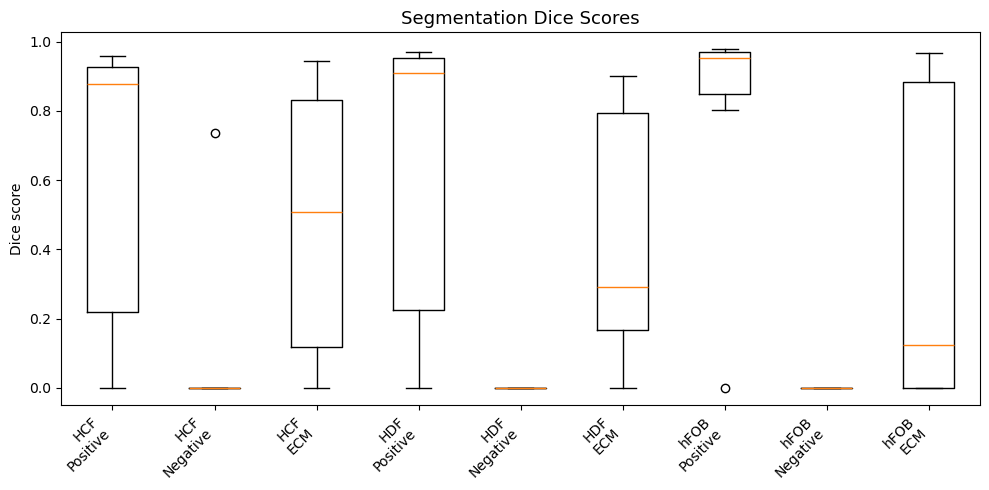

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_STATS/segmentation_boxplot_dice.png


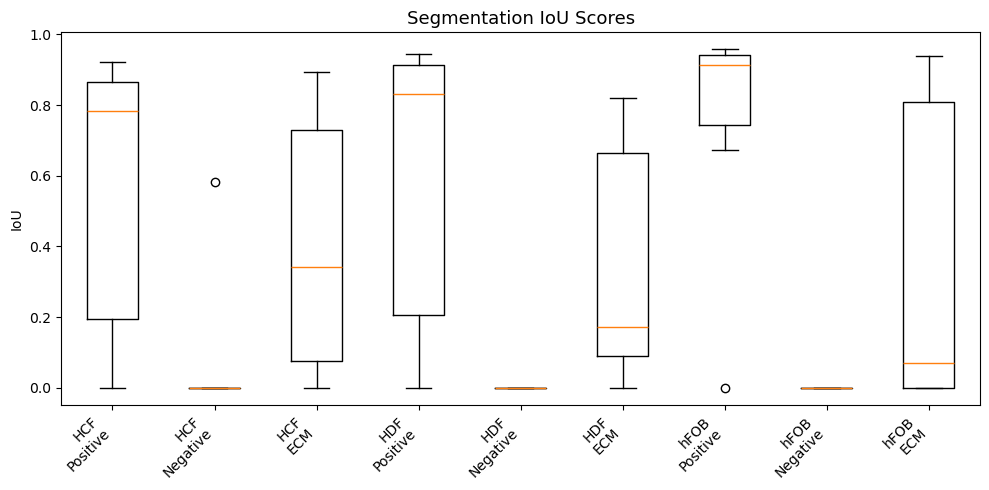

Saved: /Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_STATS/segmentation_boxplot_iou.png


In [11]:
# ==========================================
# SEGMENTATION BOXPLOTS
# ==========================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

seg_path = "/Users/catalinaamurrio/Desktop/Thesis/tiles_png_nuclei/FINAL_METRICS_90/metrics_selected_90.csv"
output_dir = Path("/Users/catalinaamurrio/Desktop/Thesis/PAPER_SEGMENTATION_STATS")
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(seg_path)

print("Columns:")
print(df.columns.tolist())

# ---- EDIT THESE ONLY IF NEEDED AFTER PRINTING COLUMNS ----
dice_col = "dice"
iou_col = "iou"
file_col = None

# try to detect a filename/image column
for candidate in ["file", "filename", "image", "image_name", "mask_name", "sample"]:
    if candidate in df.columns:
        file_col = candidate
        break

if file_col is None:
    raise ValueError("Could not find a filename column. Check the printed columns and set file_col manually.")

# -------------------------------------------
# Parse cell line and condition from filename
# -------------------------------------------
def parse_cell_line(name):
    name = str(name)
    if "HCF" in name:
        return "HCF"
    elif "HDF" in name:
        return "HDF"
    elif "HFOB" in name:
        return "hFOB"
    return "Unknown"

def parse_condition(name):
    name = str(name)
    if "ECM" in name:
        return "ECM"
    elif "Positive" in name or "control" in name or "Control" in name:
        return "Positive"
    elif "Negative" in name or "negative" in name:
        return "Negative"
    return "Unknown"

df["cell_line"] = df[file_col].apply(parse_cell_line)
df["condition"] = df[file_col].apply(parse_condition)

conditions_order = ["Positive", "Negative", "ECM"]

# ----------------------------
# Dice boxplot
# ----------------------------
fig, ax = plt.subplots(figsize=(10, 5))

groups = []
labels = []

for cell_line in ["HCF", "HDF", "hFOB"]:
    for cond in conditions_order:
        sub = df[(df["cell_line"] == cell_line) & (df["condition"] == cond)]
        if len(sub) > 0:
            groups.append(sub[dice_col].dropna().values)
            labels.append(f"{cell_line}\n{cond}")

ax.boxplot(groups)
ax.set_title("Segmentation Dice Scores", fontsize=13)
ax.set_ylabel("Dice score")
ax.set_xticklabels(labels, rotation=45, ha="right")
plt.tight_layout()

dice_out = output_dir / "segmentation_boxplot_dice.png"
plt.savefig(dice_out, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {dice_out}")

# ----------------------------
# IoU boxplot
# ----------------------------
fig, ax = plt.subplots(figsize=(10, 5))

groups = []
labels = []

for cell_line in ["HCF", "HDF", "hFOB"]:
    for cond in conditions_order:
        sub = df[(df["cell_line"] == cell_line) & (df["condition"] == cond)]
        if len(sub) > 0:
            groups.append(sub[iou_col].dropna().values)
            labels.append(f"{cell_line}\n{cond}")

ax.boxplot(groups)
ax.set_title("Segmentation IoU Scores", fontsize=13)
ax.set_ylabel("IoU")
ax.set_xticklabels(labels, rotation=45, ha="right")
plt.tight_layout()

iou_out = output_dir / "segmentation_boxplot_iou.png"
plt.savefig(iou_out, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {iou_out}")

In [3]:
# Run this first to see what variables already exist
%whos

Variable               Type        Data/Info
--------------------------------------------
dataframe_columns      function    <function dataframe_columns at 0x10873ede0>
dataframe_hash         function    <function dataframe_hash at 0x1044cede0>
dtypes_str             function    <function dtypes_str at 0x104515d00>
get_dataframes         function    <function get_dataframes at 0x125b36660>
getpass                module      <module 'getpass' from '/<...>b/python3.13/getpass.py'>
hashlib                module      <module 'hashlib' from '/<...>b/python3.13/hashlib.py'>
import_pandas_safely   function    <function import_pandas_safely at 0x10873f420>
is_data_frame          function    <function is_data_frame at 0x1045151c0>
json                   module      <module 'json' from '/opt<...>on3.13/json/__init__.py'>
sys                    module      <module 'sys' (built-in)>


In [20]:
import pandas as pd
import numpy as np

# Replace morph_df with your real dataframe name
df = morph_df.copy()

# Keep only the columns we need
df = df[['cell_type', 'condition', 'area', 'circularity', 'eccentricity']].copy()

# Summary table
morph_summary = (
    df.groupby(['cell_type', 'condition'])
      .agg(
          n_nuclei=('area', 'count'),
          area_mean=('area', 'mean'),
          area_median=('area', 'median'),
          area_sd=('area', 'std'),
          circularity_mean=('circularity', 'mean'),
          circularity_median=('circularity', 'median'),
          circularity_sd=('circularity', 'std'),
          eccentricity_mean=('eccentricity', 'mean'),
          eccentricity_median=('eccentricity', 'median'),
          eccentricity_sd=('eccentricity', 'std')
      )
      .reset_index()
)

# Optional: round for cleaner display
morph_summary = morph_summary.round(3)

display(morph_summary)

,cell_type,condition,n_nuclei,area_mean,area_median,area_sd,circularity_mean,circularity_median,circularity_sd,eccentricity_mean,eccentricity_median,eccentricity_sd
0,HCF,ECM,76,5089.645,5047.0,3773.433,0.196,0.079,0.227,0.750,0.785,0.189
1,HCF,Positive,95,10891.105,9130.0,7548.882,0.098,0.045,0.133,0.656,0.652,0.208
2,HDF,ECM,66,4036.621,1798.5,5355.332,0.235,0.162,0.227,0.851,0.898,0.135
3,HDF,Positive,97,5011.505,3512.0,4767.540,0.193,0.136,0.174,0.756,0.766,0.189
4,hFOB,ECM,80,4910.412,2715.5,5082.335,0.219,0.103,0.280,0.742,0.773,0.193
5,hFOB,Positive,95,7828.674,5171.0,8107.673,0.090,0.062,0.130,0.640,0.692,0.186


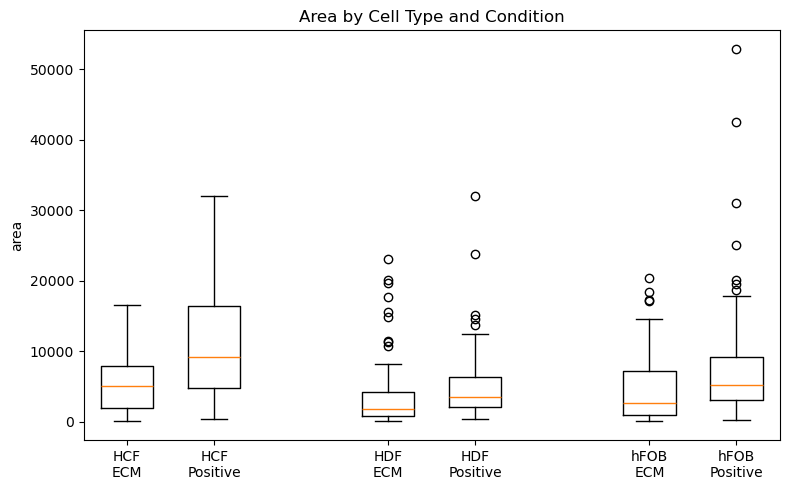

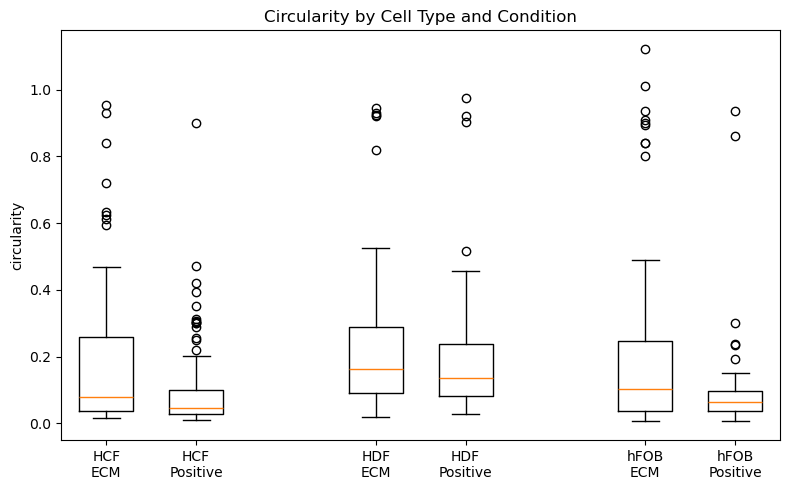

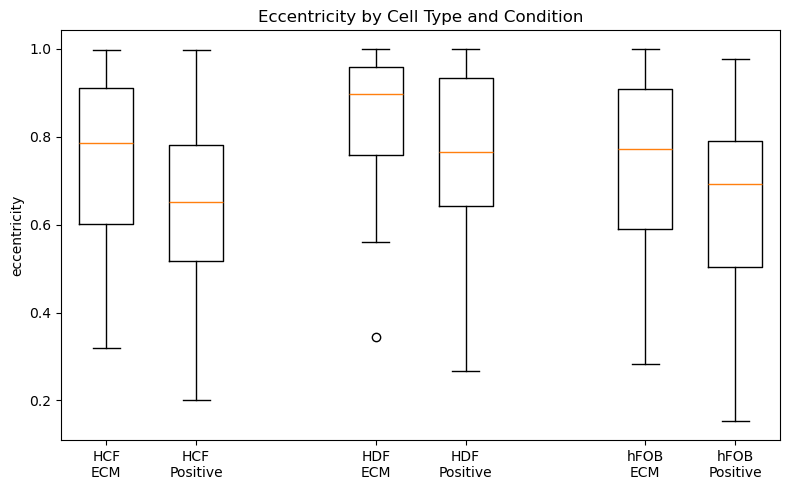

In [21]:
import matplotlib.pyplot as plt

# Replace morph_df with your real dataframe name
df = morph_df.copy()

features = ['area', 'circularity', 'eccentricity']
cell_types = df['cell_type'].unique()

for feature in features:
    plt.figure(figsize=(8, 5))
    
    positions = []
    data_to_plot = []
    labels = []
    pos = 1
    
    for cell in sorted(cell_types):
        for cond in ['ECM', 'Positive']:
            vals = df[(df['cell_type'] == cell) & (df['condition'] == cond)][feature].dropna()
            if len(vals) > 0:
                data_to_plot.append(vals)
                positions.append(pos)
                labels.append(f'{cell}\n{cond}')
                pos += 1
        pos += 1  # extra space between cell types
    
    plt.boxplot(data_to_plot, positions=positions, widths=0.6)
    plt.xticks(positions, labels, rotation=0)
    plt.ylabel(feature)
    plt.title(f'{feature.capitalize()} by Cell Type and Condition')
    plt.tight_layout()
    plt.show()

In [22]:
import pandas as pd
from scipy.stats import mannwhitneyu

# Replace morph_df with your real dataframe name
df = morph_df.copy()

features = ['area', 'circularity', 'eccentricity']
results = []

for cell in sorted(df['cell_type'].unique()):
    for feature in features:
        ecm = df[(df['cell_type'] == cell) & (df['condition'] == 'ECM')][feature].dropna()
        pos = df[(df['cell_type'] == cell) & (df['condition'] == 'Positive')][feature].dropna()
        
        if len(ecm) > 0 and len(pos) > 0:
            stat, pval = mannwhitneyu(ecm, pos, alternative='two-sided')
            
            results.append({
                'cell_type': cell,
                'feature': feature,
                'ECM_n': len(ecm),
                'Positive_n': len(pos),
                'ECM_median': ecm.median(),
                'Positive_median': pos.median(),
                'U_statistic': stat,
                'p_value': pval
            })

stats_table = pd.DataFrame(results).round(6)

display(stats_table)

,cell_type,feature,ECM_n,Positive_n,ECM_median,Positive_median,U_statistic,p_value
0,HCF,area,76,95,5047.000000,9130.000000,1928.0,0.000000
1,HCF,circularity,76,95,0.079124,0.045254,4806.0,0.000202
2,HCF,eccentricity,76,95,0.784922,0.652011,4517.0,0.004834
3,HDF,area,66,97,1798.500000,3512.000000,2151.0,0.000388
4,HDF,circularity,66,97,0.162314,0.135563,3464.0,0.374841
5,HDF,eccentricity,66,97,0.898020,0.765669,4125.0,0.001796
6,hFOB,area,80,95,2715.500000,5171.000000,2592.0,0.000298
7,hFOB,circularity,80,95,0.102850,0.062285,4747.0,0.004583
8,hFOB,eccentricity,80,95,0.772743,0.692271,4949.0,0.000582


In [23]:
stats_table_clean = stats_table.copy()
stats_table_clean['p_value'] = stats_table_clean['p_value'].apply(lambda x: f"{x:.3e}")
display(stats_table_clean)

,cell_type,feature,ECM_n,Positive_n,ECM_median,Positive_median,U_statistic,p_value
0,HCF,area,76,95,5047.000000,9130.000000,1928.0,0.000e+00
1,HCF,circularity,76,95,0.079124,0.045254,4806.0,2.020e-04
2,HCF,eccentricity,76,95,0.784922,0.652011,4517.0,4.834e-03
3,HDF,area,66,97,1798.500000,3512.000000,2151.0,3.880e-04
4,HDF,circularity,66,97,0.162314,0.135563,3464.0,3.748e-01
5,HDF,eccentricity,66,97,0.898020,0.765669,4125.0,1.796e-03
6,hFOB,area,80,95,2715.500000,5171.000000,2592.0,2.980e-04
7,hFOB,circularity,80,95,0.102850,0.062285,4747.0,4.583e-03
8,hFOB,eccentricity,80,95,0.772743,0.692271,4949.0,5.820e-04


In [24]:
def sig_label(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

stats_table_thesis = stats_table.copy()
stats_table_thesis['significance'] = stats_table_thesis['p_value'].apply(sig_label)
stats_table_thesis['p_value'] = stats_table_thesis['p_value'].apply(lambda x: f"{x:.3e}")

display(stats_table_thesis)

,cell_type,feature,ECM_n,Positive_n,ECM_median,Positive_median,U_statistic,p_value,significance
0,HCF,area,76,95,5047.000000,9130.000000,1928.0,0.000e+00,***
1,HCF,circularity,76,95,0.079124,0.045254,4806.0,2.020e-04,***
2,HCF,eccentricity,76,95,0.784922,0.652011,4517.0,4.834e-03,**
3,HDF,area,66,97,1798.500000,3512.000000,2151.0,3.880e-04,***
4,HDF,circularity,66,97,0.162314,0.135563,3464.0,3.748e-01,ns
5,HDF,eccentricity,66,97,0.898020,0.765669,4125.0,1.796e-03,**
6,hFOB,area,80,95,2715.500000,5171.000000,2592.0,2.980e-04,***
7,hFOB,circularity,80,95,0.102850,0.062285,4747.0,4.583e-03,**
8,hFOB,eccentricity,80,95,0.772743,0.692271,4949.0,5.820e-04,***


In [26]:
#Final thesis table

import pandas as pd
import numpy as np

# IMPORTANT: morph_df must already exist in memory
df = morph_df.copy()

df = df[['cell_type', 'condition', 'area', 'circularity', 'eccentricity']].copy()

morph_summary_medium = (
    df.groupby(['cell_type', 'condition'])
      .agg(
          n_nuclei=('area', 'count'),
          area_median=('area', 'median'),
          area_sd=('area', 'std'),
          circularity_median=('circularity', 'median'),
          circularity_sd=('circularity', 'std'),
          eccentricity_median=('eccentricity', 'median'),
          eccentricity_sd=('eccentricity', 'std')
      )
      .reset_index()
      .round(3)
)

display(morph_summary_medium)

morph_summary_medium.to_csv("morphometrics_summary_table.csv", index=False)

print("Exported as morphometrics_summary_table.csv")

,cell_type,condition,n_nuclei,area_median,area_sd,circularity_median,circularity_sd,eccentricity_median,eccentricity_sd
0,HCF,ECM,76,5047.0,3773.433,0.079,0.227,0.785,0.189
1,HCF,Positive,95,9130.0,7548.882,0.045,0.133,0.652,0.208
2,HDF,ECM,66,1798.5,5355.332,0.162,0.227,0.898,0.135
3,HDF,Positive,97,3512.0,4767.540,0.136,0.174,0.766,0.189
4,hFOB,ECM,80,2715.5,5082.335,0.103,0.280,0.773,0.193
5,hFOB,Positive,95,5171.0,8107.673,0.062,0.130,0.692,0.186


Exported as morphometrics_summary_table.csv


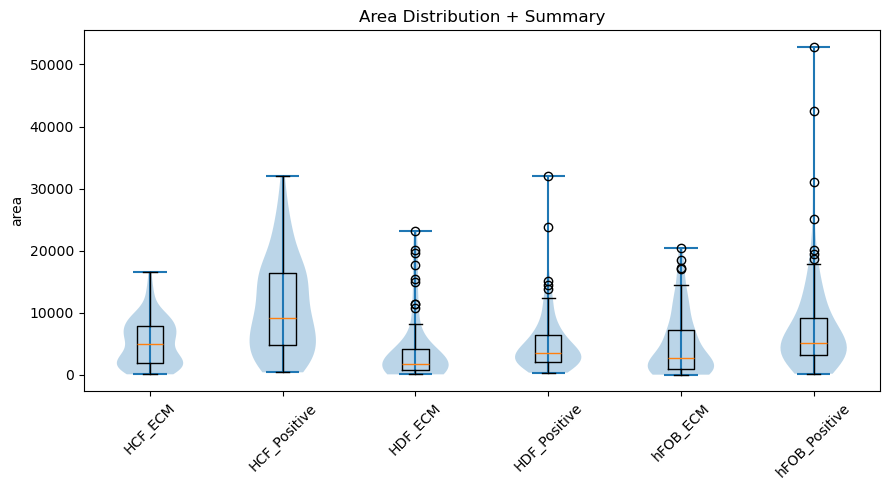

In [27]:
import matplotlib.pyplot as plt

df = morph_df.copy()
df['group'] = df['cell_type'] + '_' + df['condition']

order = [
    'HCF_ECM', 'HCF_Positive',
    'HDF_ECM', 'HDF_Positive',
    'hFOB_ECM', 'hFOB_Positive'
]

for feature in ['area']:
    data_to_plot = [df[df['group'] == g][feature].dropna() for g in order if g in df['group'].unique()]
    labels = [g for g in order if g in df['group'].unique()]

    plt.figure(figsize=(9,5))
    
    # Violin (distribution)
    plt.violinplot(data_to_plot, showmedians=False)
    
    # Boxplot overlay (structure)
    plt.boxplot(data_to_plot, widths=0.2)

    plt.xticks(range(1, len(labels)+1), labels, rotation=45)
    plt.ylabel(feature)
    plt.title(f'{feature.capitalize()} Distribution + Summary')

    plt.tight_layout()
    plt.show()

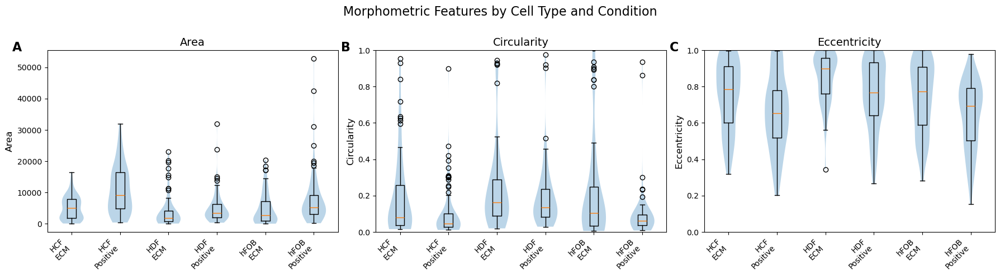

<Figure size 640x480 with 0 Axes>

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Make sure morph_df exists
df = morph_df.copy()

# Create combined group label
df['group'] = df['cell_type'] + '\n' + df['condition']

# Desired plotting order
order = [
    'HCF\nECM', 'HCF\nPositive',
    'HDF\nECM', 'HDF\nPositive',
    'hFOB\nECM', 'hFOB\nPositive'
]

# Features and panel letters
features = ['area', 'circularity', 'eccentricity']
panel_letters = ['A', 'B', 'C']
panel_titles = ['Area', 'Circularity', 'Eccentricity']

# Create figure with 3 side-by-side panels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature, letter, title in zip(axes, features, panel_letters, panel_titles):
    data_to_plot = [
        df[df['group'] == g][feature].dropna()
        for g in order
        if g in df['group'].unique()
    ]
    labels = [g for g in order if g in df['group'].unique()]
    positions = np.arange(1, len(labels) + 1)

    # Violin plot
    violins = ax.violinplot(
        data_to_plot,
        positions=positions,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Boxplot overlay
    ax.boxplot(
        data_to_plot,
        positions=positions,
        widths=0.18,
        patch_artist=False
    )

    # Formatting
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_title(title, fontsize=14)
    ax.set_ylabel(title, fontsize=12)

    # Set y-limits for shape metrics
    if feature in ['circularity', 'eccentricity']:
        ax.set_ylim(0, 1)

    # Panel letter
    ax.text(
        -0.12, 1.05, letter,
        transform=ax.transAxes,
        fontsize=16,
        fontweight='bold',
        va='top',
        ha='left'
    )

# Overall layout
fig.suptitle('Morphometric Features by Cell Type and Condition', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.82)

# Save figure
plt.savefig("morphometrics_three_panel_figure.png", dpi=300, bbox_inches='tight')

plt.show()

plt.draw()

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig("/Users/catalinaamurrio/Desktop/morphometrics_three_panel_figure.png",
            dpi=300)

plt.show()